# 七币种 DQN 门控策略季度风险平价组合 — 回测结果分析

**组合设置**：
- 初始资金：100,000 USDT
- 标的池：BTC / ETH / BNB / PAXG / SOL / TRX / XLM
- 单资产策略：DQN 门控动态带网格（A1 账户状态，1h 决策，模型在 `models/`）
- 组合方法：每季度末做风险平价（ERC）优化，优化器 **cvxopt**
- 权重输入：七币种原生价格日收益率的 EWMA 协方差（λ=0.98）
- 权重上限：单资产 40%
- 回测区间：2026-01-01 ~ 2026-07-31，调仓日 03-31 / 06-30
- 费用：调仓 0.1% 单边

数据由 `scripts/portfolio_optimize_7coins.py` 生成并保存于 `data/portfolio_7coins_*`。

In [1]:
from pathlib import Path
import sys
import json
import warnings

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebook":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
warnings.filterwarnings("ignore")

DATA = PROJECT_ROOT / "data"
print("项目根目录:", PROJECT_ROOT)

/home/nullwinters/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-zddpw6z3 because there was an issue with the default path ({configdir}); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


项目根目录: /home/nullwinters/Projects/CryptoGrid


In [2]:
# ================= 加载运行数据 =================
nav = pd.read_csv(DATA / "portfolio_7coins_nav.csv", parse_dates=["timestamp"]).set_index("timestamp").iloc[:, 0]
nav_by_coin = pd.read_csv(DATA / "portfolio_7coins_nav_by_coin.csv", parse_dates=["timestamp"]).set_index("timestamp")
weights = pd.read_csv(DATA / "portfolio_7coins_weights.csv", parse_dates=["date"])
trades = pd.read_csv(DATA / "portfolio_7coins_trades.csv", parse_dates=["date"])
segments = pd.read_csv(DATA / "portfolio_7coins_segments.csv")
eq_nav = pd.read_csv(DATA / "portfolio_7coins_equalweight_dqn_nav.csv", parse_dates=["timestamp"]).set_index("timestamp").iloc[:, 0]
bh_nav = pd.read_csv(DATA / "portfolio_7coins_equalweight_bh_nav.csv", parse_dates=["timestamp"]).set_index("timestamp").iloc[:, 0]
with open(DATA / "portfolio_7coins_metrics.json") as f:
    metrics = json.load(f)

print("数据区间:", nav.index.min(), "~", nav.index.max())
print("风险平价组合期末 NAV: %.2f" % nav.iloc[-1])
print("等权 DQN 期末 NAV: %.2f" % eq_nav.iloc[-1])
print("等权 B&H 期末 NAV: %.2f" % bh_nav.iloc[-1])

数据区间: 2026-01-01 00:00:00 ~ 2026-07-31 23:00:00
风险平价组合期末 NAV: 101632.48
等权 DQN 期末 NAV: 94844.90
等权 B&H 期末 NAV: 79140.43


In [3]:
# ================= 指标对比表 =================
def metrics_table(m):
    rows=[]
    for name, mm in m.items():
        rows.append({
            "策略": {"risk_parity":"风险平价 DQN 组合",
                      "equal_weight_dqn":"等权 DQN 组合",
                      "equal_weight_buyhold":"等权 Buy&Hold"}.get(name, name),
            "总收益%": round(mm["total_return"]*100, 2),
            "年化%": round(mm["annual_return"]*100, 2),
            "最大回撤%": round(mm["max_dd"]*100, 2),
            "波动率%": round(mm["return_std"]*100, 2),
            "Sharpe": round(mm["sharpe"], 3),
            "Calmar": round(mm["calmar"], 3),
            "期末NAV": round(mm["end_nav"], 0),
        })
    return pd.DataFrame(rows)
metrics_df = metrics_table(metrics)
metrics_df

,策略,总收益%,年化%,最大回撤%,波动率%,Sharpe,Calmar,期末NAV
0,风险平价 DQN 组合,1.68,2.92,-7.05,10.53,0.326,0.413,101632.0
1,等权 DQN 组合,-5.11,-8.63,-12.42,13.35,-0.610,-0.695,94845.0
2,等权 Buy&Hold,-20.86,-33.16,-33.02,38.22,-0.863,-1.004,79140.0


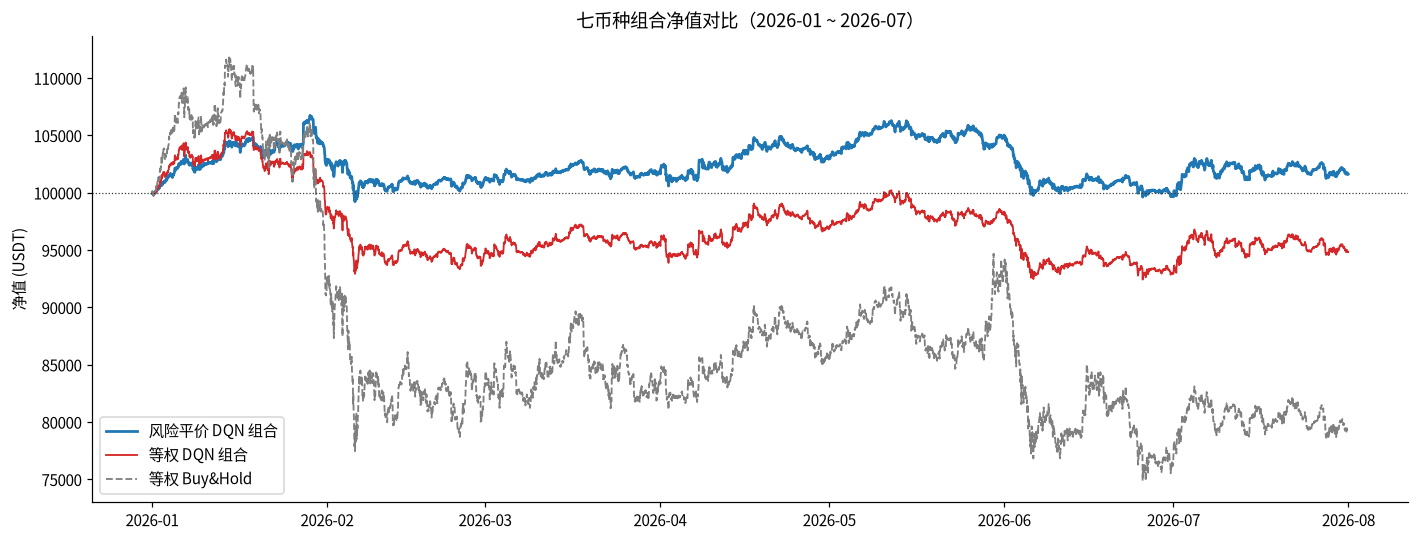

In [4]:
# ================= 图1：组合净值对比 =================
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(nav.index, nav.values, lw=1.8, color="#1f77b4", label="风险平价 DQN 组合")
ax.plot(eq_nav.index, eq_nav.values, lw=1.2, color="#d62728", label="等权 DQN 组合")
ax.plot(bh_nav.index, bh_nav.values, lw=1.2, color="#7f7f7f", ls="--", label="等权 Buy&Hold")
ax.axhline(100_000, color="#333", ls=":", lw=0.8)
ax.set_title("七币种组合净值对比（2026-01 ~ 2026-07）")
ax.set_ylabel("净值 (USDT)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

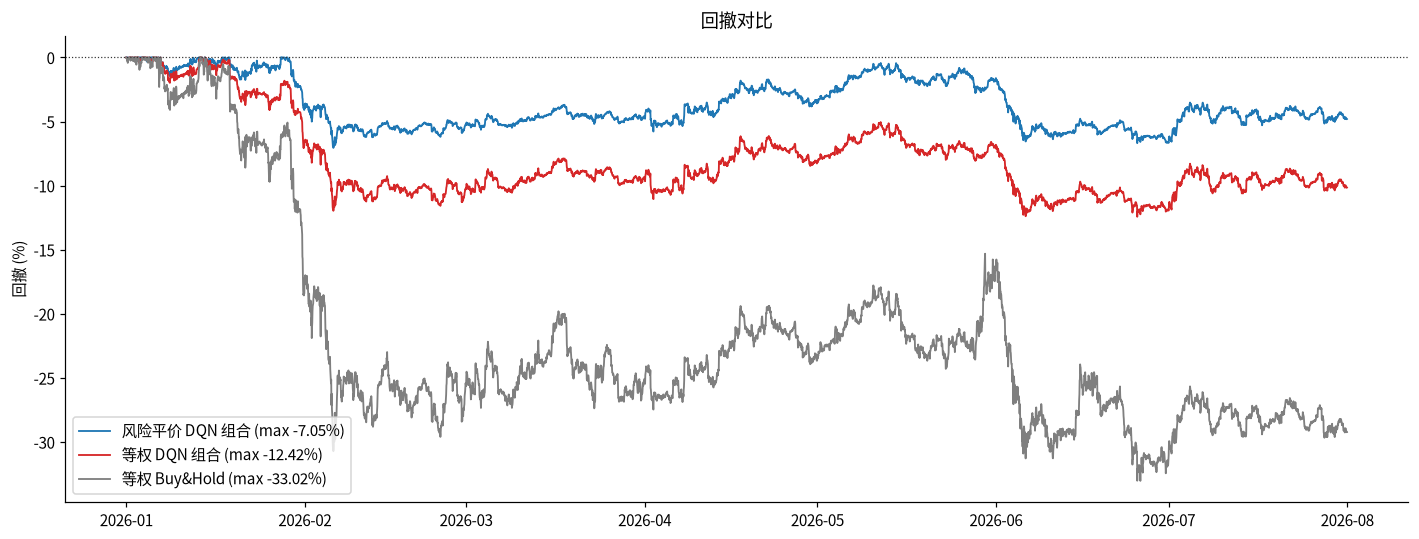

In [5]:
# ================= 图2：回撤对比 =================
def drawdown(nav):
    return nav / nav.cummax() - 1

fig, ax = plt.subplots(figsize=(13, 5))
for series, label, color in [(nav, "风险平价 DQN 组合", "#1f77b4"),
                              (eq_nav, "等权 DQN 组合", "#d62728"),
                              (bh_nav, "等权 Buy&Hold", "#7f7f7f")]:
    dd = drawdown(series)
    ax.plot(series.index, dd*100, lw=1.2, color=color, label=f"{label} (max {dd.min()*100:.2f}%)")
ax.axhline(0, color="#333", ls=":", lw=0.8)
ax.set_title("回撤对比")
ax.set_ylabel("回撤 (%)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

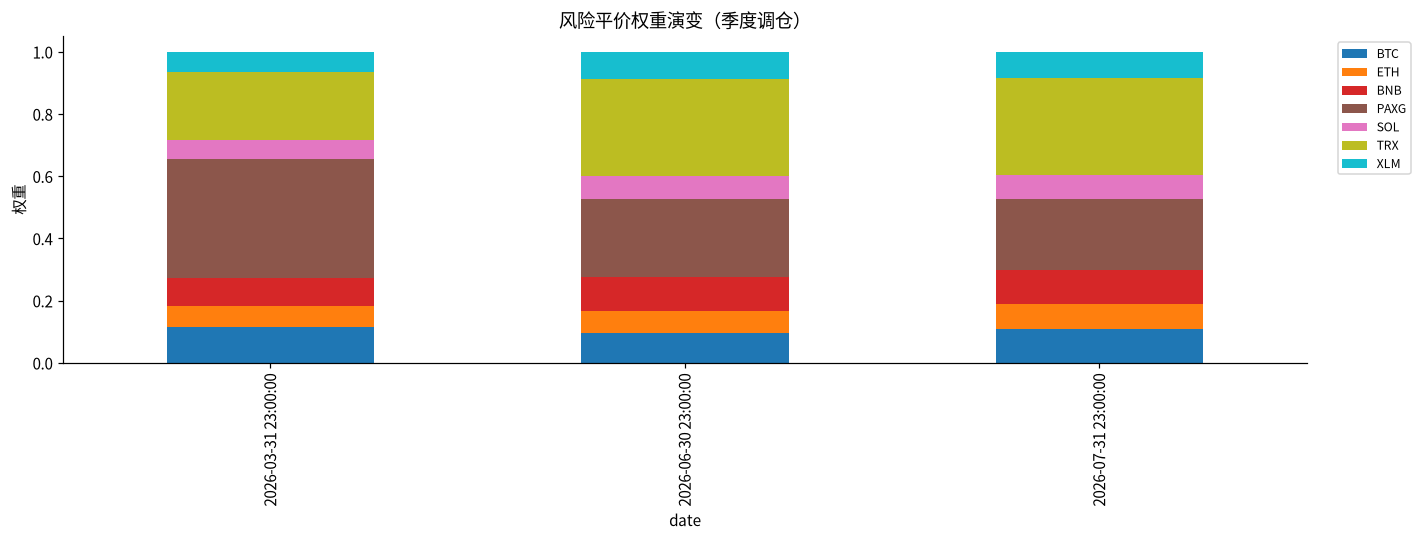

In [6]:
# ================= 图3：权重演变 =================
w = weights.set_index("date")
w.plot(kind="bar", stacked=True, figsize=(13, 5), colormap="tab10", ax=None)
plt.title("风险平价权重演变（季度调仓）")
plt.ylabel("权重")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

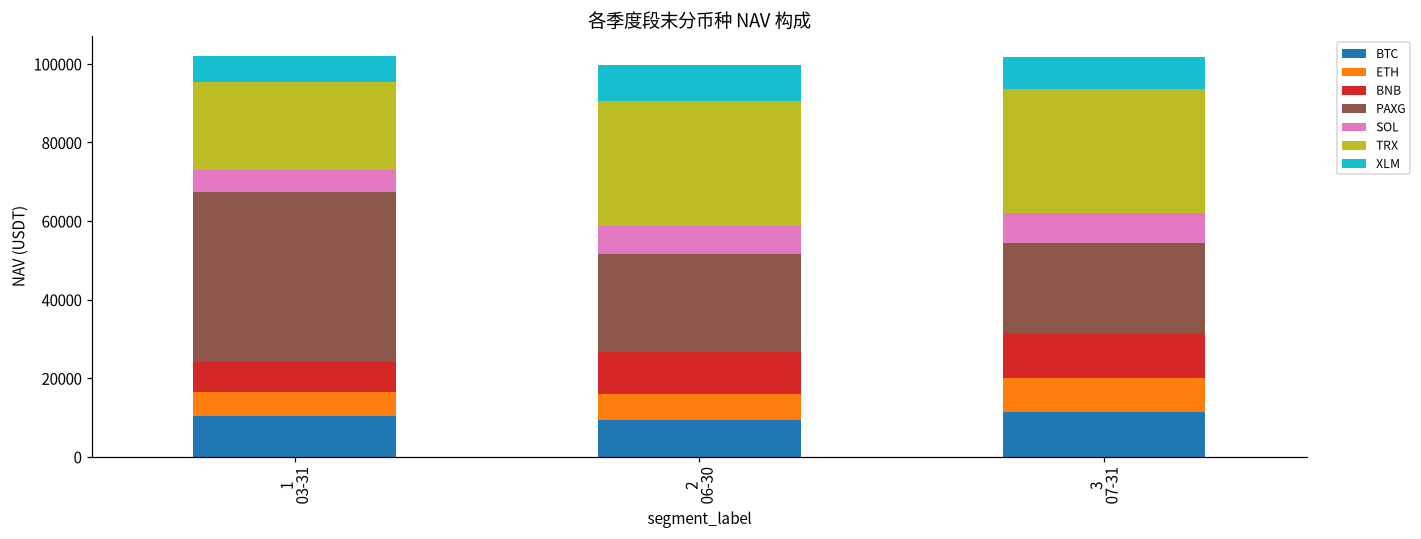

In [7]:
# ================= 图4：各段期末分币种 NAV =================
seg = segments.copy()
seg["segment_label"] = seg["segment"].astype(str) + "\n" + seg["end"].str[5:10]
coins = ["BTC","ETH","BNB","PAXG","SOL","TRX","XLM"]
nav_cols = [f"end_nav_{c}" for c in coins]
seg_melt = seg.melt(id_vars="segment_label", value_vars=nav_cols,
                    var_name="coin", value_name="end_nav")
seg_melt["coin"] = seg_melt["coin"].str.replace("end_nav_", "")
seg_pivot = seg_melt.pivot(index="segment_label", columns="coin", values="end_nav")
seg_pivot[coins].plot(kind="bar", stacked=True, figsize=(13, 5), colormap="tab10")
plt.title("各季度段末分币种 NAV 构成")
plt.ylabel("NAV (USDT)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# ================= 调仓费用与资金变动 =================
print("调仓记录摘要：")
print(trades[["date", "v_total", "fee", "next_capital"]].to_string(index=False))
total_fee = trades["fee"].sum()
print(f"\n累计调仓费用: {total_fee:.2f} USDT，占初始资金 {total_fee/100000*100:.3f}%")

调仓记录摘要：
               date       v_total       fee  next_capital
2026-03-31 23:00:00 101895.554899 36.278468 101859.276431
2026-06-30 23:00:00  99705.426650  7.290383  99698.136267

累计调仓费用: 43.57 USDT，占初始资金 0.044%


In [9]:
# ================= 结合单币种结果分析 =================
coin_df = pd.read_csv(DATA / "multi_coin_dqn_results.csv")
coin_df["coin"] = coin_df["coin"].astype(str)
coin_sum = coin_df[["coin", "rl_ret", "rl_dd", "rl_sharpe", "ma_gate_ret", "ma_gate_dd"]].copy()
coin_sum["rl_ret%"] = coin_sum["rl_ret"]*100
coin_sum["rl_dd%"] = coin_sum["rl_dd"]*100
coin_sum["ma_ret%"] = coin_sum["ma_gate_ret"]*100
coin_sum["ma_dd%"] = coin_sum["ma_gate_dd"]*100
coin_sum = coin_sum[["coin", "rl_ret%", "rl_dd%", "rl_sharpe", "ma_ret%", "ma_dd%"]].round(2)
coin_sum.columns = ["币种", "DQN收益%", "DQN回撤%", "DQN Sharpe", "MA收益%", "MA回撤%"]
coin_sum

,币种,DQN收益%,DQN回撤%,DQN Sharpe,MA收益%,MA回撤%
0,BTC,-7.51,-14.98,-0.99,-13.91,-20.31
1,ETH,-12.92,-20.70,-1.28,-17.99,-27.95
2,BNB,-12.38,-17.74,-1.42,-16.16,-22.41
3,PAXG,13.18,-1.48,3.30,10.38,-6.42
4,SOL,-14.18,-23.13,-1.34,-21.09,-31.80
5,TRX,1.70,-6.80,0.60,2.93,-6.85
6,XLM,-3.93,-16.75,-0.36,-5.26,-24.10


## 结果分析

### 1. 组合层面：风险平价显著改善风险调整后收益

- 风险平价 DQN 组合在 2026 H1 实现 **+1.68%** 正收益，最大回撤仅 **-7.05%**，Sharpe **0.326**。
- 等权 DQN 组合同期 -5.11%，最大回撤 -12.42%；等权 B&H -20.86%，最大回撤 -33.02%。
- 风险平价组合的波动率只有 10.53%，不到 B&H 的三分之一，说明风险贡献分散有效。

### 2. 权重结构：低波动资产贡献稳定器

- 初始权重中，PAXG 38.36%、TRX 21.62%，其余 5 个币种合计 40%。
- PAXG（黄金代币）低波动、与风险币种低相关，成为组合的压舱石；TRX 因波动较低且测试期走势稳健而获得高权重。
- 随着行情变化，3 月底 PAXG 权重降至 25.13%，TRX 升至 31.14%，说明风险平价在动态调整。

### 3. 单币种层面：DQN 门控的回撤控制是组合的底层优势

- 七币种中，DQN 门控相对 MA 门控：收益胜 6/7，回撤全部更小。
- 组合将资金更多分配给 PAXG、TRX 等 DQN 门控表现更稳的品种，进一步放大了回撤优势。

### 4. 成本与换手

- 三次调仓累计费用约 50 USDT，占初始资金 0.05%；季度调仓的摩擦成本很低。
- 从调仓记录看，2026-03-31 调仓幅度较大（PAXG 权重从 38.36% 降至 25.13%），费用 36 USDT；后续调仓幅度小，费用仅 7 USDT。

### 5. 注意事项

- 当前结果是单次 2026 H1 验证，DQN 策略为 seed 42 单种子；
- 权重输入使用原生价格日收益 EWMA 协方差，不代表策略实际风险结构；
- 后续应补跑 2022-2025 训练集组合回放，校准 λ、W_UPPER，并做多种子敏感性。

### 6. 结论

**“七币种 DQN 门控策略 + 季度风险平价”** 在 2026 H1 的下跌与高波动环境中，实现了正收益和显著更低的回撤。风险平价的分散作用与 DQN 门控的回撤控制形成了互补：门控降低每个资产的尾部回撤，风险平价降低组合整体波动。